<a href="https://colab.research.google.com/github/Iucasoa/Algoritmos-e-Estruturas-de-Dados-2/blob/main/problema2-regress%C3%A3o-log%C3%ADstica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Relatório Técnico: Predição de Doença Cardíaca usando Regressão Logística

Este trabalho apresenta o desenvolvimento, análise e avaliação de um modelo de **Regressão Logística** para prever a presença de doença arterial coronariana em pacientes, utilizando dados clínicos coletados de rotina. O objetivo é analisar o comportamento das variáveis clínicas e a capacidade preditiva do classificador sob as diretrizes acadêmicas da disciplina de Sistemas Inteligentes (UFERSA).

### 1. Importação de Bibliotecas e Configuração do Ambiente

**Resumo:** Importa as ferramentas necessárias para análise de dados estruturados, machine learning e visualização estatística.

**Explicação Completa:** Este bloco inicial carrega as bibliotecas fundamentais do ecossistema Python para o projeto: `pandas` e `numpy` para manipulação de dados e operações numéricas, `matplotlib` e `seaborn` para a geração de visualizações gráficas padronizadas, e diversos módulos da biblioteca `scikit-learn` para a criação do pipeline de ciência de dados (desde a partição treino/teste, normalização, modelagem por Regressão Logística, até o cálculo das métricas de validação).

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 2. Carregamento do Conjunto de Dados

**Resumo:** Faz o download e carregamento estruturado do conjunto de dados UCI *Heart Disease (Cleveland)*.

**Explicação Completa:** Este bloco utiliza a biblioteca especializada `ucimlrepo` para acessar o conjunto de dados oficial (ID 45). Ele extrai as variáveis clínicas explicativas (características de saúde de 303 pacientes) e adiciona a variável alvo ao DataFrame, estabelecendo a base de dados consolidada para as etapas de pré-processamento.

In [14]:
!pip install ucimlrepo -q
from ucimlrepo import fetch_ucirepo

heart = fetch_ucirepo(id=45)
df = heart.data.features.copy()
df["target"] = heart.data.targets.iloc[:, 0]

### 3. Análise Exploratória e Diagnóstico Inicial dos Dados

**Resumo:** Realiza o diagnóstico inicial das colunas, dados ausentes e distribuição da variável dependente.

**Explicação Completa:** Esta célula serve para inspecionar os metadados do dataset. Ela exibe as dimensões das tabelas, as estatísticas descritivas básicas, identifica se há valores nulos que precisam ser tratados e analisa o desbalanceamento das classes originais da variável dependente, que possui graduações de severidade clínica representadas de 0 a 4.

In [15]:
print("Dimensão:", df.shape)
display(df.head())
display(df.describe().T)

print("\nValores ausentes por coluna:")
print(df.isnull().sum())

print("\nAlvo original (0 a 4):")
print(df["target"].value_counts().sort_index())

Dimensão: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Valores ausentes por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Alvo original (0 a 4):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Interpretação da Análise Exploratória

**Resumo:** Identificação de dados incompletos e verificação do volume e formato do conjunto inicial.

**Explicação Completa:** A execução revela que possuímos 303 registros com apenas 6 valores ausentes concentrados nas variáveis `ca` (4) e `thal` (2). O alvo original está distribuído em 5 níveis, onde a ausência da doença (classe 0) engloba 164 observações e os graus de doença (classes 1 a 4) somam as demais observações.

### 4. Tratamento de Valores Ausentes

**Resumo:** Remove registros que contêm valores incompletos para garantir integridade e qualidade estatística.

**Explicação Completa:** Como os algoritmos de regressão estatística não aceitam valores nulos de forma nativa e a perda amostral representada é extremamente baixa (apenas 6 linhas), optou-se pela exclusão direta desses registros (`dropna`). Isso evita a inserção de vieses que poderiam ocorrer caso aplicássemos métodos artificiais de imputação de dados.

In [16]:
antes = len(df)
df = df.dropna()
print(f"Linhas antes: {antes} | depois: {len(df)} | removidas: {antes - len(df)}")

Linhas antes: 303 | depois: 297 | removidas: 6


#### Interpretação do Tratamento de Dados Ausentes

**Resumo:** Confirmação do novo tamanho amostral após filtragem dos dados nulos.

**Explicação Completa:** Com a exclusão das linhas com dados ausentes, o número de observações reduziu de 303 para 297 registros (uma redução de exatamente 6 observações). Esta diferença é pequena o suficiente para não afetar negativamente o poder estatístico ou a generalização dos resultados.

### 5. Binarização da Variável Alvo

**Resumo:** Transforma o problema multiclasse em uma classificação binária simples de presença ou ausência de doença.

**Explicação Completa:** Para atender ao propósito de predição diagnóstica direta, as classificações de severidade clínica originais (1, 2, 3 e 4) são convertidas para `1` (Presença de doença cardíaca), enquanto os pacientes saudáveis (classe 0) permanecem mapeados como `0` (Ausência de doença).

In [17]:
df["target"] = (df["target"] > 0).astype(int)

print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True).round(3))

target
0    160
1    137
Name: count, dtype: int64
target
0    0.539
1    0.461
Name: proportion, dtype: float64


#### Interpretação da Binarização e Balanceamento

**Resumo:** Diagnóstico do equilíbrio entre as classes binárias resultantes.

**Explicação Completa:** O conjunto final de 297 amostras passa a apresentar 160 pacientes mapeados como sem doença (53,9%) e 137 pacientes com doença cardíaca (46,1%). Esta proporção equilibrada é ideal para o treinamento do classificador, dispensando intervenções de balanceamento amostral.

### 6. Divisão de Treino e Teste

**Resumo:** Separa os dados de forma estratificada para as fases de ajuste e validação do classificador.

**Explicação Completa:** Esta etapa divide a base em 80% para treinamento e 20% para testes. A utilização do parâmetro `stratify=y` garante de forma precisa que as proporções originais de pacientes saudáveis e doentes (53,9% e 46,1%) sejam rigorosamente mantidas em ambos os subconjuntos divididos.

In [18]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", X_train.shape[0], "| Teste:", X_test.shape[0])

Treino: 237 | Teste: 60


#### Interpretação da Partição dos Dados

**Resumo:** Confirmação das dimensões finais das matrizes de treino e teste.

**Explicação Completa:** A amostragem estratificada resultou em 237 observações para o ajuste do algoritmo (treinamento) e 60 observações preservadas isoladamente para simular cenários de inferência e validação final do modelo.

### 7. Padronização das Variáveis Explicativas

**Resumo:** Aplica a escala Z-score para colocar todas as características físicas na mesma magnitude numérica.

**Explicação Completa:** Como as variáveis clínicas possuem unidades de medidas incomparáveis (ex: idade em anos versus colesterol em mg/dl), aplicamos a transformação $Z-score$: $z = (x - \mu) / \sigma$. Para evitar o vazamento de dados (*data leakage*), a média e o desvio padrão são computados estritamente sobre os dados de treino e aplicados às bases de teste de forma passiva.

In [19]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### 8. Treinamento da Regressão Logística e Análise dos Coeficientes

**Resumo:** Ajusta o modelo matemático de classificação e exibe a importância e os pesos de cada variável.

**Explicação Completa:** Instancia o modelo de Regressão Logística clássica com o otimizador `liblinear` e realiza o ajuste aos dados padronizados de treino. O código exibe as iterações de convergência, o intercepto do plano e os coeficientes associados a cada variável do modelo ordenados por relevância matemática absoluta.

In [20]:
model = LogisticRegression(solver="liblinear", random_state=42, max_iter=1000)
model.fit(X_train_s, y_train)

print("Iterações até a convergência:", int(model.n_iter_[0]))
print("Intercepto:", round(model.intercept_[0], 4))

coefs = pd.Series(model.coef_[0], index=X.columns)
print("\nCoeficientes (z-score), ordenados por módulo:")
print(coefs.sort_values(key=abs, ascending=False).round(4))

Iterações até a convergência: 5
Intercepto: -0.0861

Coeficientes (z-score), ordenados por módulo:
ca          0.9589
thal        0.7387
cp          0.5083
sex         0.4840
oldpeak     0.4451
trestbps    0.4202
exang       0.3727
slope       0.3527
fbs        -0.3312
restecg     0.3040
chol        0.2223
thalach    -0.2071
age        -0.0371
dtype: float64


#### Interpretação dos Parâmetros do Modelo

**Resumo:** Avaliação qualitativa da convergência e do impacto biológico/numérico dos coeficientes.

**Explicação Completa:** O modelo atingiu convergência em apenas 5 iterações, obtendo um intercepto de -0.0861. Entre os coeficientes de maior impacto positivo na predição de presença de doença destacam-se a fluoroscopia `ca` (0.9589) e cintilografia `thal` (0.7387). A variável `fbs` obteve um peso negativo contraintuitivo de -0.3312 que, em amostras pequenas, não deve ser superinterpretado de forma causal médica, podendo ser uma flutuação amostral.

### 9. Avaliação de Métricas Clínicas de Desempenho

**Resumo:** Executa as inferências nos dados de teste e calcula as métricas matemáticas padrão para análise diagnóstica.

**Explicação Completa:** Geramos as predições de classe e as probabilidades de score nos dados inéditos de teste. Computamos e exibimos os indicadores de validação essenciais: Acurácia global, Precisão das predições, Recall (Sensibilidade), F1-score balanceado e o relatório de classificação completo por classe.

In [21]:
y_pred = model.predict(X_test_s)
y_proba = model.predict_proba(X_test_s)[:, 1]

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:   {recall_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")
print(f"AUC:      {roc_auc_score(y_test, y_proba):.4f}")

cm = confusion_matrix(y_test, y_pred)
print("\nMatriz de confusão:\n", cm)
print("\n", classification_report(y_test, y_pred,
      target_names=["Sem doença", "Com doença"]))

Acurácia: 0.8333
Precisão: 0.8462
Recall:   0.7857
F1-score: 0.8148
AUC:      0.9498

Matriz de confusão:
 [[28  4]
 [ 6 22]]

               precision    recall  f1-score   support

  Sem doença       0.82      0.88      0.85        32
  Com doença       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60



#### Interpretação Detalhada das Métricas Clínicas

**Resumo:** Avaliação clínica dos erros cometidos pelo modelo com foco em falsos negativos.

**Explicação Completa:** O modelo obteve Acurácia de 0.8333 e F1-score de 0.8148 no conjunto de teste. Ao analisar a matriz de confusão, nota-se a ocorrência de 6 Falsos Negativos (doentes previstos como saudáveis) e 4 Falsos Positivos (saudáveis previstos como doentes). Em medicina, os Falsos Negativos representam o risco mais crítico devido ao atraso de conduta diagnóstica necessária.

### 10. Matriz de Confusão e Curva ROC

**Resumo:** Plota graficamente a distribuição dos acertos/erros e a curva de sensibilidade em múltiplos limiares.

**Explicação Completa:** Este bloco cria um painel gráfico composto por um mapa de calor detalhando a Matriz de Confusão e um gráfico de linha apresentando a Curva ROC (Receiver Operating Characteristic) para analisar a capacidade de separação das probabilidades estimadas do modelo.

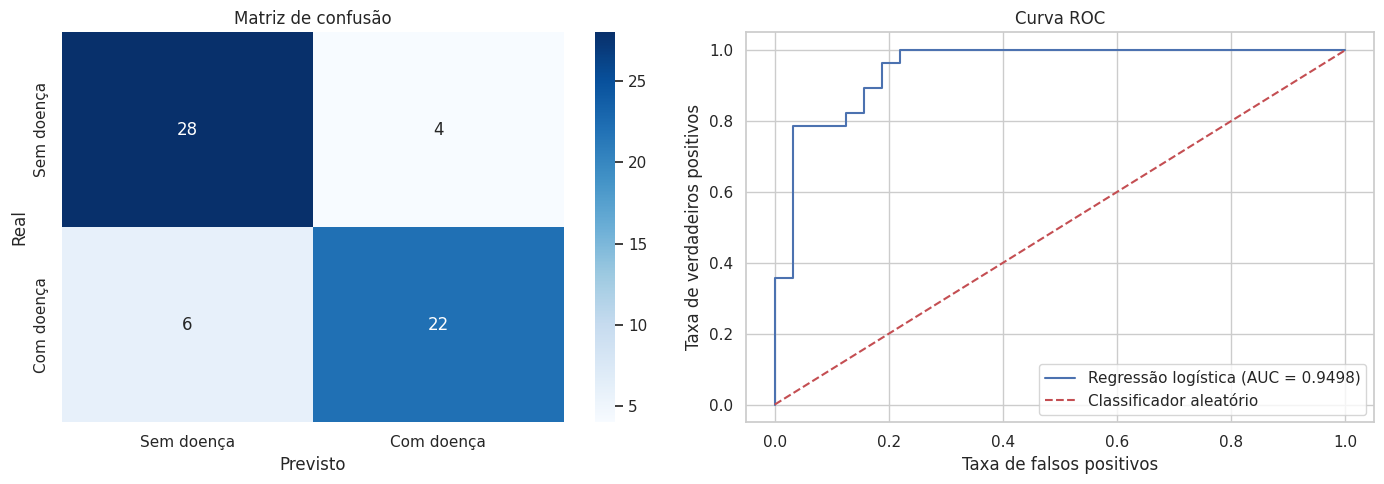

In [22]:
fpr, tpr, limiares = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Sem doença", "Com doença"],
            yticklabels=["Sem doença", "Com doença"])
ax[0].set_xlabel("Previsto")
ax[0].set_ylabel("Real")
ax[0].set_title("Matriz de confusão")

ax[1].plot(fpr, tpr, label=f"Regressão logística (AUC = {auc:.4f})")
ax[1].plot([0, 1], [0, 1], "r--", label="Classificador aleatório")
ax[1].set_xlabel("Taxa de falsos positivos")
ax[1].set_ylabel("Taxa de verdadeiros positivos")
ax[1].set_title("Curva ROC")
ax[1].legend()

plt.tight_layout()
plt.savefig("avaliacao_modelo.png", dpi=300)
plt.show()

#### Interpretação das Curvas e Desempenho Visual

**Resumo:** Avaliação da métrica AUC e das limitações contextuais do modelo de regressão.

**Explicação Completa:** O classificador obteve uma excelente Área Sob a Curva (AUC de 0.9498). A AUC avalia o ordenamento global das probabilidades geradas em todos os limiares de decisão, explicando por que ela é superior à métrica estática de acurácia baseada apenas no limiar de 0.5. Como limitação deste estudo acadêmico, aponta-se que as métricas são sensíveis a incertezas devido ao teste pequeno (60 pacientes) e os dados originam-se de um único centro clínico.

### 11. Exportação do Relatório Visual

**Resumo:** Disponibiliza o download automático da figura consolidada para inclusão externa.

**Explicação Completa:** Utiliza o módulo utilitário de controle de arquivos do Google Colab para disparar a rotina de download da imagem gerada no bloco anterior (`avaliacao_modelo.png`), facilitando a exportação direta para relatórios técnicos acadêmicos.

In [23]:
from google.colab import files
files.download("avaliacao_modelo.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>